In [21]:
import pandas as pd
import xlrd

df = pd.read_excel("default of credit card clients.xls", header=1)
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [22]:
# %pip install xlrd

In [23]:
df.shape

(30000, 25)

In [24]:
df.head()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [25]:
df = df.rename(columns={"default payment next month": "default"})
#df = df.drop(columns=["ID"])
df.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default']

In [26]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [27]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df[col].value_counts().sort_index())
    print()

SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64



In [28]:
df["PAY_0"].value_counts().sort_index()

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [31]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after:", df.shape)

Duplicates before: 0
Shape after: (30000, 25)


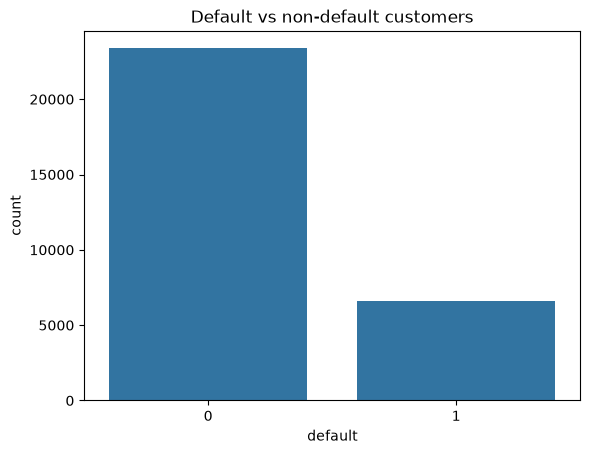

default
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="default", data=df)
plt.title("Default vs non-default customers")
plt.show()

print(df["default"].value_counts(normalize=True))

In [33]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


PAY_0
-2    0.132294
-1    0.167781
 0    0.128113
 1    0.339479
 2    0.691414
 3    0.757764
 4    0.684211
 5    0.500000
 6    0.545455
 7    0.777778
 8    0.578947
Name: default, dtype: float64


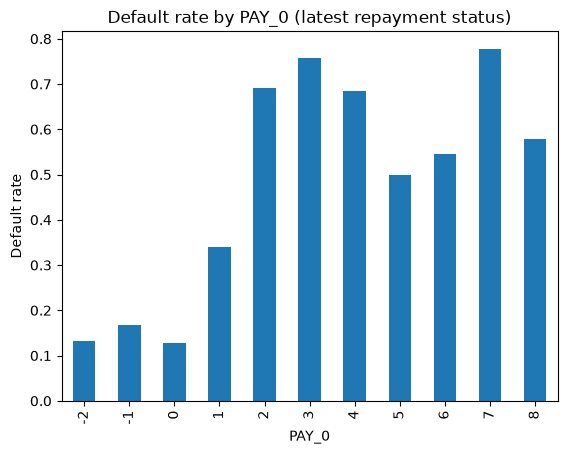

In [34]:
rate = df.groupby("PAY_0")["default"].mean()
print(rate)

rate.plot(kind="bar")
plt.ylabel("Default rate")
plt.title("Default rate by PAY_0 (latest repayment status)")
plt.show()

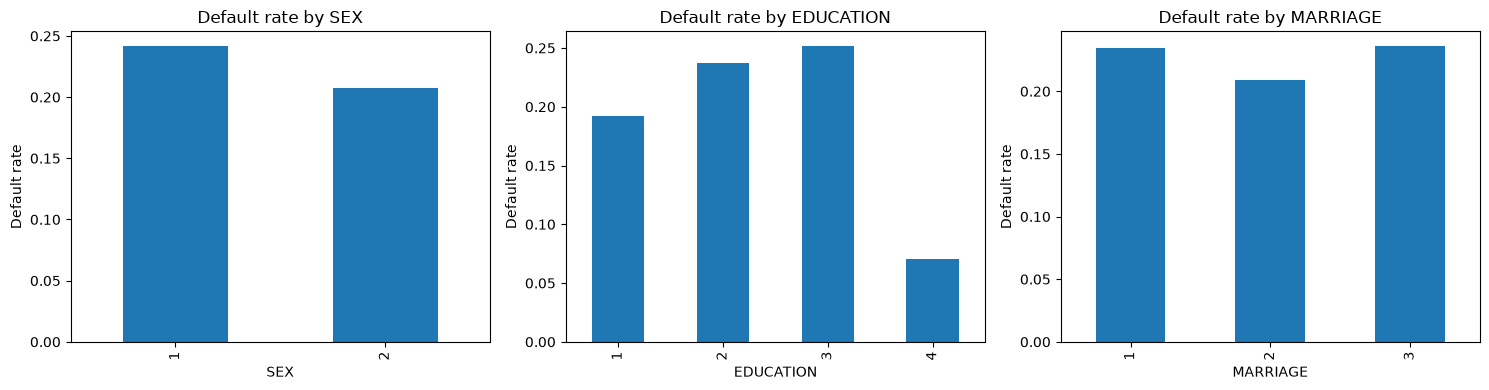

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    df.groupby(col)["default"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Default rate by {col}")
    ax.set_ylabel("Default rate")

plt.tight_layout()
plt.show()

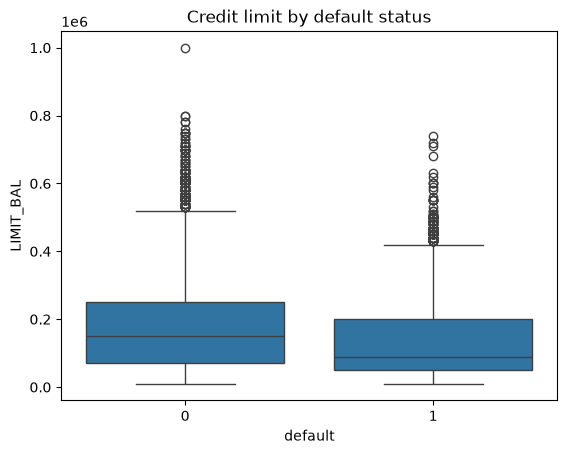

In [36]:
sns.boxplot(x="default", y="LIMIT_BAL", data=df)
plt.title("Credit limit by default status")
plt.show()

In [37]:
df = df.drop(columns=["ID"],errors='ignore')    

In [38]:
print("ID" in df.columns)

False


default      1.000000
PAY_0        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
EDUCATION    0.033842
AGE          0.013890
BILL_AMT6   -0.005372
BILL_AMT5   -0.006760
BILL_AMT4   -0.010156
BILL_AMT3   -0.014076
BILL_AMT2   -0.014193
BILL_AMT1   -0.019644
MARRIAGE    -0.027575
SEX         -0.039961
PAY_AMT6    -0.053183
PAY_AMT5    -0.055124
PAY_AMT3    -0.056250
PAY_AMT4    -0.056827
PAY_AMT2    -0.058579
PAY_AMT1    -0.072929
LIMIT_BAL   -0.153520
Name: default, dtype: float64


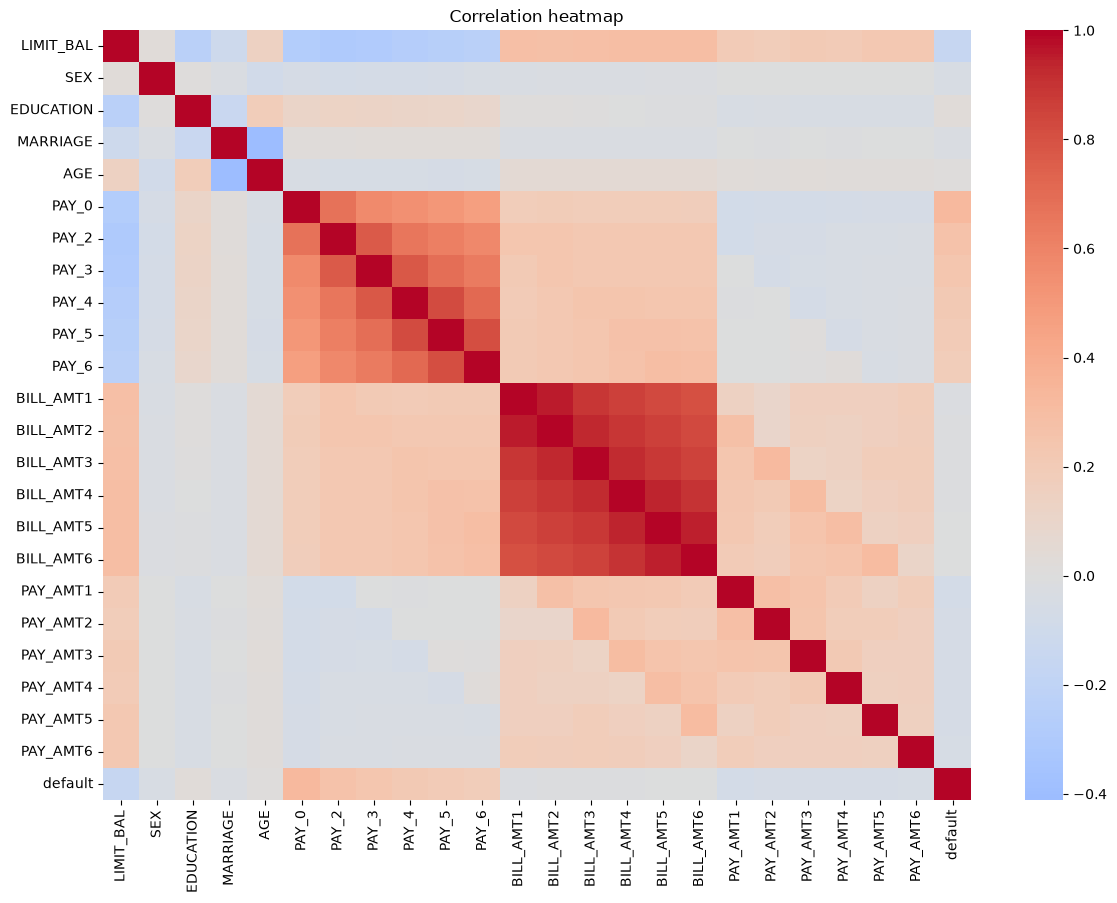

In [39]:
corr = df.corr()
print(corr["default"].sort_values(ascending=False))

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

In [40]:
pay_cols  = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
amt_cols  = [f"PAY_AMT{i}" for i in range(1, 7)]

df["avg_delay"]   = df[pay_cols].mean(axis=1)
df["max_delay"]   = df[pay_cols].max(axis=1)
df["months_late"] = (df[pay_cols] > 0).sum(axis=1)
df["avg_bill"]    = df[bill_cols].mean(axis=1)
df["total_paid"]  = df[amt_cols].sum(axis=1)
df["utilization"] = df["avg_bill"] / df["LIMIT_BAL"]
df["pay_ratio"]   = df["total_paid"] / df[bill_cols].sum(axis=1).clip(lower=1)
df["pay_ratio"]   = df["pay_ratio"].clip(upper=5)

df[["avg_delay", "max_delay", "months_late", "utilization", "pay_ratio"]].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_delay,30000.0,-0.182439,0.982176,-2.00000,-0.833333,0.000000,0.000000,6.000000
max_delay,30000.0,0.438733,1.345154,-2.00000,0.000000,0.000000,2.000000,8.000000
months_late,30000.0,0.834200,1.554303,0.00000,0.000000,0.000000,1.000000,6.000000
utilization,30000.0,0.373048,0.351890,-0.23259,0.029997,0.284834,0.687929,5.364308
pay_ratio,30000.0,0.403886,0.700129,0.00000,0.041311,0.088017,0.613705,5.000000


In [41]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df.drop(columns=["default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

(24000, 30) (6000, 30)
0.22120833333333334 0.22116666666666668


In [42]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score)

def make_pipe(model):
    return Pipeline([("prep", clone(preprocess)), ("model", model)])

def evaluate(name, pipe):
    pred  = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

lr = make_pipe(LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
evaluate("Logistic Regression", lr)

{'Model': 'Logistic Regression',
 'Precision': 0.6373983739837399,
 'Recall': 0.29540316503391106,
 'F1': 0.40370751802265703,
 'ROC-AUC': 0.7443498066704929}

In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

dt = make_pipe(DecisionTreeClassifier(max_depth=5, random_state=42))
rf = make_pipe(RandomForestClassifier(
        n_estimators=200, max_depth=10, random_state=42, n_jobs=-1))

dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

evaluate("Decision Tree", dt), evaluate("Random Forest", rf)

({'Model': 'Decision Tree',
  'Precision': 0.675,
  'Recall': 0.3458929917106255,
  'F1': 0.45739910313901344,
  'ROC-AUC': 0.7590915343494696},
 {'Model': 'Random Forest',
  'Precision': 0.6532033426183844,
  'Recall': 0.35342878673700073,
  'F1': 0.458679706601467,
  'ROC-AUC': 0.7769408703754561})

                     Precision  Recall     F1  ROC-AUC
Model                                                 
Logistic Regression      0.637   0.295  0.404    0.744
Decision Tree            0.675   0.346  0.457    0.759
Random Forest            0.653   0.353  0.459    0.777


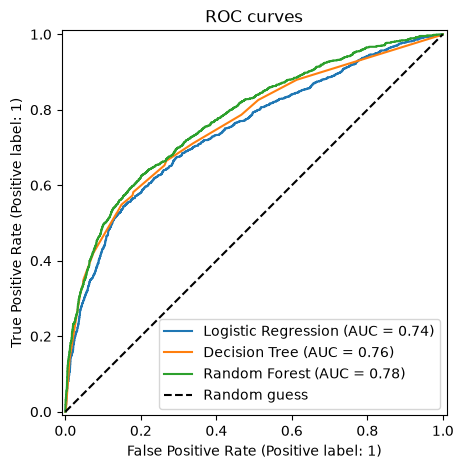

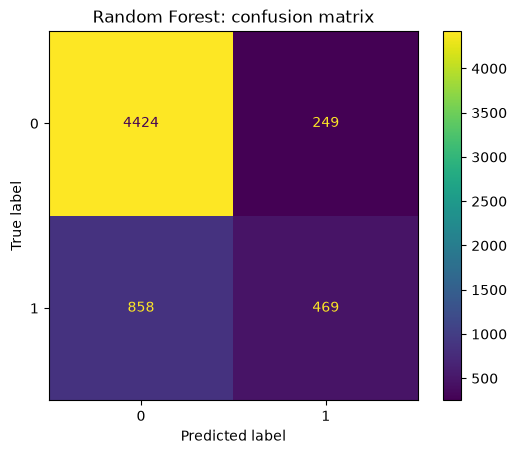

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

models = {"Logistic Regression": lr, "Decision Tree": dt, "Random Forest": rf}

results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
print(results.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
plt.title("ROC curves")
plt.show()

ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test)
plt.title("Random Forest: confusion matrix")
plt.show()

In [45]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

lr_bal = make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"))
rf_bal = make_pipe(RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight="balanced",
        random_state=42, n_jobs=-1))
lr_bal.fit(X_train, y_train)
rf_bal.fit(X_train, y_train)

models["LogReg (balanced)"] = lr_bal
models["RandomForest (balanced)"] = rf_bal
results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
print(results.round(3))

                         Precision  Recall     F1  ROC-AUC
Model                                                     
Logistic Regression          0.637   0.295  0.404    0.744
Decision Tree                0.675   0.346  0.457    0.759
Random Forest                0.653   0.353  0.459    0.777
LogReg (balanced)            0.440   0.601  0.508    0.747
RandomForest (balanced)      0.483   0.602  0.536    0.777


In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf_bal, X_train, y_train, cv=cv, scoring="roc_auc")
print(scores.round(3), "mean:", scores.mean().round(3))

[0.786 0.784 0.775 0.788 0.789] mean: 0.784


In [47]:
print("ID" in X.columns)

False


In [48]:
proba = rf_bal.predict_proba(X_test)[:, 1]
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (proba >= t).astype(int)
    print(t, round(precision_score(y_test, pred), 3),
             round(recall_score(y_test, pred), 3),
             round(f1_score(y_test, pred), 3))

0.3 0.312 0.858 0.457
0.4 0.397 0.698 0.506
0.5 0.483 0.602 0.536
0.6 0.563 0.518 0.539


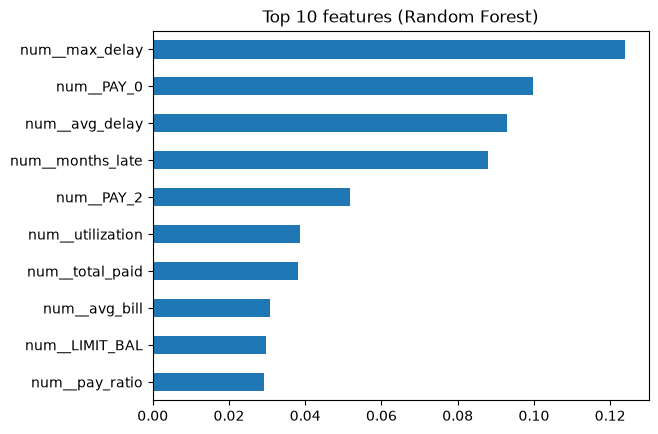

array([[0.69729728, 0.30270272]])

In [49]:
import joblib

names = rf_bal.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_bal.named_steps["model"].feature_importances_, index=names)
ax = imp.sort_values(ascending=False).head(10).plot(kind="barh")
ax.invert_yaxis()
plt.title("Top 10 features (Random Forest)")
plt.show()

joblib.dump(rf_bal, "credit_model.joblib")

loaded = joblib.load("credit_model.joblib")
loaded.predict_proba(X_test.iloc[[0]])

In [50]:
import os
os.makedirs("images", exist_ok=True)

In [51]:
plt.savefig("images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [53]:
import os
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score

assert "ID" not in X.columns, "Drop the ID column, then Restart -> Run All"

res = results.round(3)
table = "\n".join(
    ["| Model | Precision | Recall | F1 | ROC-AUC |", "|---|---|---|---|---|"]
    + [f"| {n} | {r['Precision']} | {r['Recall']} | {r['F1']} | {r['ROC-AUC']} |"
       for n, r in res.iterrows()])
best = res["ROC-AUC"].idxmax()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = cross_val_score(rf_bal, X_train, y_train, cv=cv, scoring="roc_auc")

proba = rf_bal.predict_proba(X_test)[:, 1]
thr = {}
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    thr[t] = (precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p))
thr_table = "\n".join(
    ["| Threshold | Precision | Recall | F1 |", "|---|---|---|---|"]
    + [f"| {t} | {v[0]:.3f} | {v[1]:.3f} | {v[2]:.3f} |" for t, v in thr.items()])

names = rf_bal.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_bal.named_steps["model"].feature_importances_, index=names)
top = ", ".join(n.split("__")[-1] for n in imp.sort_values(ascending=False).head(5).index)

imgs = "\n".join(f"![{t}](images/{f})" for t, f in
    [("ROC curves", "roc_curves.png"), ("Confusion matrix", "confusion_matrix.png"),
     ("Feature importance", "feature_importance.png")] if os.path.exists(f"images/{f}"))

demo = ""
if os.path.exists("app.py"):
    demo = ("\n## Demo app (optional)\n"
            "```\npython -m streamlit run app.py\n```\n"
            "A small Streamlit form that estimates default probability. It approximates "
            "six months of history using one average bill and one average payment.\n")

readme = f"""# Task 1: Credit Scoring Model

## Objective
Predict whether a credit card customer will default on payment next month (1 = default).

## Dataset
UCI "Default of Credit Card Clients" (Taiwan, 2005): https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- {len(df)} customers after removing duplicates
- {X.shape[1]} features ({X.shape[1] - 7} original + 7 engineered)
- Default rate: {df['default'].mean() * 100:.1f}% (imbalanced, so accuracy alone is misleading)
- File used: `default of credit card clients.xls` (loaded with `header=1`)

## Approach
1. Cleaned undocumented category codes, removed duplicates, dropped the ID column
2. EDA: default rate by payment status, demographics, correlations
3. Feature engineering: avg_delay, max_delay, months_late, avg_bill, total_paid, utilization, pay_ratio
4. Preprocessing: one-hot encoding + scaling inside a Pipeline (no data leakage)
5. Stratified 80/20 split ({len(X_train)} train / {len(X_test)} test)
6. Models: Logistic Regression, Decision Tree, Random Forest (plain and class-balanced)
7. Evaluation: Precision, Recall, F1, ROC-AUC, 5-fold cross-validation

## Results (test set)
{table}

Best ROC-AUC: **{best}** ({res.loc[best, 'ROC-AUC']}).
5-fold CV ROC-AUC of the balanced Random Forest: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}.

## Threshold analysis (balanced Random Forest)
{thr_table}

Moving the threshold from 0.6 to 0.3 changes recall from {thr[0.6][1]:.3f} to {thr[0.3][1]:.3f} and precision from {thr[0.6][0]:.3f} to {thr[0.3][0]:.3f}. A bank that wants to catch more defaulters accepts lower precision.

Top 5 features (Random Forest): {top}.

{imgs}

## Limitations
- The threshold was compared on the test set; a separate validation set would be cleaner.
- Data is from 2005 and from one country.
{demo}
## How to run
Open `credit_scoring.ipynb` and click Run All.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)
print(readme)

# Task 1: Credit Scoring Model

## Objective
Predict whether a credit card customer will default on payment next month (1 = default).

## Dataset
UCI "Default of Credit Card Clients" (Taiwan, 2005): https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- 30000 customers after removing duplicates
- 30 features (23 original + 7 engineered)
- Default rate: 22.1% (imbalanced, so accuracy alone is misleading)
- File used: `default of credit card clients.xls` (loaded with `header=1`)

## Approach
1. Cleaned undocumented category codes, removed duplicates, dropped the ID column
2. EDA: default rate by payment status, demographics, correlations
3. Feature engineering: avg_delay, max_delay, months_late, avg_bill, total_paid, utilization, pay_ratio
4. Preprocessing: one-hot encoding + scaling inside a Pipeline (no data leakage)
5. Stratified 80/20 split (24000 train / 6000 test)
6. Models: Logistic Regression, Decision Tree, Random Forest (plain and class-balanced)
7. Evaluation